# Caltech

In [ ]:
# ================================================================
# TRANSFER LEARNING WITH RESNET50 ON CALTECH-101
# ================================================================

# ---------- 1. Setup ----------
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import f1_score

SEED = 42
IMG_SIZE = 224                      # size ResNet50 was trained on
BATCH_SIZE = 32
DATA_DIR = "/content/drive/MyDrive/SEM7/caltech-101"

tf.random.set_seed(SEED)
np.random.seed(SEED)

# ---------- 2. Load and split the data ----------
full_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=None, shuffle=False)

CLASS_NAMES = full_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
n_total = full_ds.cardinality().numpy()
print("Classes:", NUM_CLASSES, "  Images:", n_total)

# Shuffle once. reshuffle_each_iteration=False keeps the order fixed,
# so labels, predictions and images always line up.
full_ds = full_ds.shuffle(n_total, seed=SEED, reshuffle_each_iteration=False)

# 20% test, 10% of the rest for validation, remaining 72% for training
n_test = int(0.2 * n_total)
n_val = int(0.1 * (n_total - n_test))
test_raw = full_ds.take(n_test)
val_raw = full_ds.skip(n_test).take(n_val)
train_raw = full_ds.skip(n_test + n_val)

def preprocess(image, label):
    return preprocess_input(tf.cast(image, tf.float32)), label

train_ds = (train_raw.map(preprocess).shuffle(1000, seed=SEED)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = val_raw.map(preprocess).batch(BATCH_SIZE)
test_ds = test_raw.map(preprocess).batch(BATCH_SIZE)

# ---------- 3. Pretrained base + new layers ----------
base = ResNet50(weights="imagenet", include_top=False,
                input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False              # freeze the ImageNet weights

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.RandomFlip("horizontal")(inputs)     # augmentation (training only)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomZoom(0.1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = models.Model(inputs, outputs)

# ---------- 4. Train the new head ----------
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history1 = model.fit(train_ds, validation_data=val_ds, epochs=5)

# ---------- 5. Fine-tune the top layers ----------
base.trainable = True
for layer in base.layers[:-30]:     # freeze everything except the last 30 layers
    layer.trainable = False
for layer in base.layers:           # keep BatchNorm frozen
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),   # small learning rate
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history2 = model.fit(train_ds, validation_data=val_ds, epochs=5)

# ---------- 6. Evaluate ----------
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)

print(f"Test loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")
print("Check (should match accuracy):", round(np.mean(y_true == y_pred), 4))
print("Macro F1-score:", round(f1_score(y_true, y_pred, average="macro"), 4))

# ---------- 7. Plot training history ----------
loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]
acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]
epochs = range(1, len(loss) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(epochs, loss, label="train")
ax1.plot(epochs, val_loss, label="validation")
ax1.set_title("Loss")
ax2.plot(epochs, acc, label="train")
ax2.plot(epochs, val_acc, label="validation")
ax2.set_title("Accuracy")
for ax in (ax1, ax2):
    ax.axvline(5.5, color="gray", linestyle="--")   # fine-tuning starts after epoch 5
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)
plt.savefig("resnet_caltech101_training.png", dpi=150)
plt.show()

# ---------- 8. Show predictions ----------
images = [img.numpy().astype("uint8") for img, _ in test_raw.take(8)]
plt.figure(figsize=(14, 7))
for i, img in enumerate(images):
    true_name = CLASS_NAMES[y_true[i]]
    pred_name = CLASS_NAMES[y_pred[i]]
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(f"T: {true_name}\nP: {pred_name}",
              color="green" if true_name == pred_name else "red", fontsize=9)
    plt.axis("off")
plt.suptitle("Predictions (green = correct, red = wrong)")
plt.savefig("resnet_caltech101_predictions.png", dpi=150)
plt.show()

# Intel image classification

In [ ]:
# ================================================================
# TRANSFER LEARNING WITH RESNET50 ON INTEL IMAGE CLASSIFICATION
# ================================================================

# ---------- 1. Setup ----------
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import f1_score

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
DATA_DIR = "/content/drive/MyDrive/SEM7/intel-image"   # folder with one subfolder per class

tf.random.set_seed(SEED)
np.random.seed(SEED)

# ---------- 2. Load and split the data ----------
full_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=None, shuffle=False)

CLASS_NAMES = full_ds.class_names          # read from the folder names
NUM_CLASSES = len(CLASS_NAMES)
n_total = full_ds.cardinality().numpy()
print("Classes:", CLASS_NAMES, "  Images:", n_total)

# Shuffle once, keeping the order fixed afterwards
full_ds = full_ds.shuffle(n_total, seed=SEED, reshuffle_each_iteration=False)

# 20% test, 10% of the rest for validation, remaining 72% for training
n_test = int(0.2 * n_total)
n_val = int(0.1 * (n_total - n_test))
test_raw = full_ds.take(n_test)
val_raw = full_ds.skip(n_test).take(n_val)
train_raw = full_ds.skip(n_test + n_val)

def preprocess(image, label):
    return preprocess_input(tf.cast(image, tf.float32)), label

train_ds = (train_raw.map(preprocess).shuffle(1000, seed=SEED)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = val_raw.map(preprocess).batch(BATCH_SIZE)
test_ds = test_raw.map(preprocess).batch(BATCH_SIZE)

# ---------- 3. Pretrained base + new layers ----------
base = ResNet50(weights="imagenet", include_top=False,
                input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

# ---------- 4. Train the new layers ----------
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history1 = model.fit(train_ds, validation_data=val_ds, epochs=5)

# ---------- 5. Fine-tune the top layers ----------
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history2 = model.fit(train_ds, validation_data=val_ds, epochs=5)

# ---------- 6. Evaluate ----------
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)

print(f"Test loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")
print("Check (should match accuracy):", round(np.mean(y_true == y_pred), 4))
print("Macro F1-score:", round(f1_score(y_true, y_pred, average="macro"), 4))

# ---------- 7. Plot training history ----------
loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]
acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]
epochs = range(1, len(loss) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(epochs, loss, label="train")
ax1.plot(epochs, val_loss, label="validation")
ax1.set_title("Loss")
ax2.plot(epochs, acc, label="train")
ax2.plot(epochs, val_acc, label="validation")
ax2.set_title("Accuracy")
for ax in (ax1, ax2):
    ax.axvline(5.5, color="gray", linestyle="--")
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)
plt.savefig("intel_training.png", dpi=150)
plt.show()

# ---------- 8. Show predictions ----------
images = [img.numpy().astype("uint8") for img, _ in test_raw.take(8)]
plt.figure(figsize=(14, 7))
for i, img in enumerate(images):
    true_name = CLASS_NAMES[y_true[i]]
    pred_name = CLASS_NAMES[y_pred[i]]
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(f"T: {true_name}\nP: {pred_name}",
              color="green" if true_name == pred_name else "red", fontsize=9)
    plt.axis("off")
plt.suptitle("Predictions (green = correct, red = wrong)")
plt.savefig("intel_predictions.png", dpi=150)
plt.show()

# Fashion MNIST

Found 625 files belonging to 11 classes.
Classes: ['Ankle-boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt-top', 'Trouser', 'train']   Images: 625


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 11)             │        22,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,610,251 (90.07 MB)

 Trainable params: 22,539 (88.04 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 24s 399ms/step - accuracy: 0.8422 - loss: 0.5540 - val_accuracy: 1.0000 - val_loss: 1.8815e-05
Epoch 2/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 209ms/step - accuracy: 1.0000 - loss: 2.1427e-05 - val_accuracy: 1.0000 - val_loss: 1.0180e-06
Epoch 3/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 212ms/step - accuracy: 1.0000 - loss: 3.1629e-06 - val_accuracy: 1.0000 - val_loss: 4.9353e-07
Epoch 4/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 212ms/step - accuracy: 1.0000 - loss: 3.7181e-06 - val_accuracy: 1.0000 - val_loss: 4.1485e-07
Epoch 5/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 213ms/step - accuracy: 1.0000 - loss: 3.2986e-06 - val_accuracy: 1.0000 - val_loss: 4.0054e-07
Epoch 1/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 419ms/step - accuracy: 1.0000 - loss: 7.5870e-07 - val_accuracy: 1.0000 - val_loss: 7.1526e-08
Epoch 2/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 246ms/step - accuracy: 1.0000 - loss: 4.8000e-07 - val_accuracy: 1.0000 - val_loss: 9.5367e-09
Epoch 3/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 257ms/step - accu

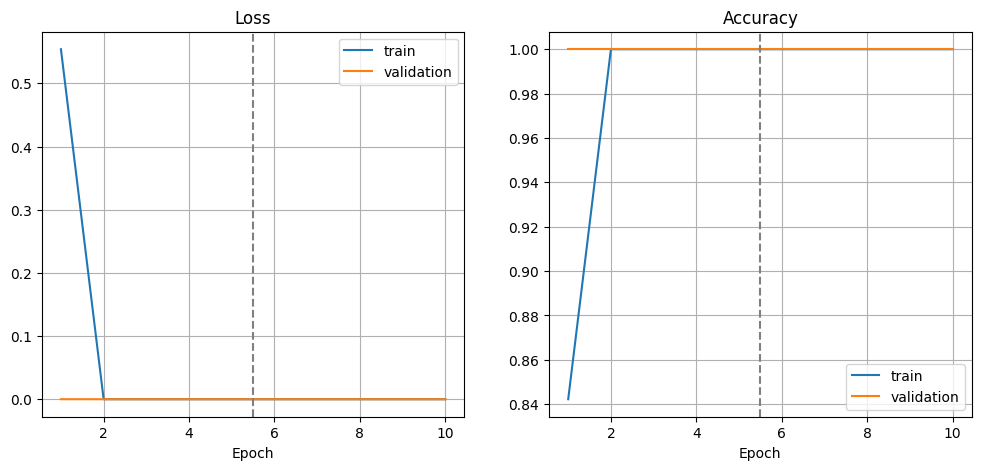

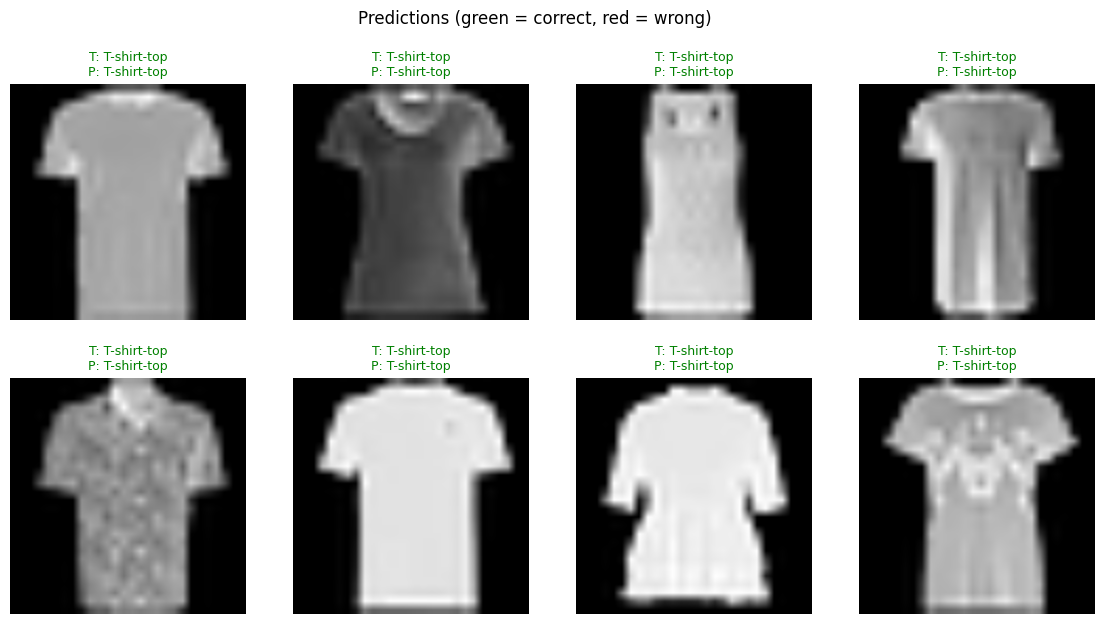

In [1]:
# ================================================================
# TRANSFER LEARNING WITH RESNET50 ON FASHION MNIST (IMAGE FOLDERS)
# ================================================================

# ---------- 1. Setup ----------
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import f1_score

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
DATA_DIR = "/content/drive/MyDrive/SEM7/fashion mnist"   # folder with one subfolder per class

tf.random.set_seed(SEED)
np.random.seed(SEED)

# ---------- 2. Load and split the data ----------
full_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=None, shuffle=False)

CLASS_NAMES = full_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
n_total = full_ds.cardinality().numpy()
print("Classes:", CLASS_NAMES, "  Images:", n_total)

full_ds = full_ds.shuffle(n_total, seed=SEED, reshuffle_each_iteration=False)

n_test = int(0.2 * n_total)
n_val = int(0.1 * (n_total - n_test))
test_raw = full_ds.take(n_test)
val_raw = full_ds.skip(n_test).take(n_val)
train_raw = full_ds.skip(n_test + n_val)

def preprocess(image, label):
    return preprocess_input(tf.cast(image, tf.float32)), label

train_ds = (train_raw.map(preprocess).shuffle(1000, seed=SEED)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = val_raw.map(preprocess).batch(BATCH_SIZE)
test_ds = test_raw.map(preprocess).batch(BATCH_SIZE)

# ---------- 3. Pretrained base + new layers ----------
base = ResNet50(weights="imagenet", include_top=False,
                input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

# ---------- 4. Train the new layers ----------
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history1 = model.fit(train_ds, validation_data=val_ds, epochs=5)

# ---------- 5. Fine-tune the top layers ----------
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history2 = model.fit(train_ds, validation_data=val_ds, epochs=5)

# ---------- 6. Evaluate ----------
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)

print(f"Test loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")
print("Check (should match accuracy):", round(np.mean(y_true == y_pred), 4))
print("Macro F1-score:", round(f1_score(y_true, y_pred, average="macro"), 4))

# ---------- 7. Plot training history ----------
loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]
acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]
epochs = range(1, len(loss) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(epochs, loss, label="train")
ax1.plot(epochs, val_loss, label="validation")
ax1.set_title("Loss")
ax2.plot(epochs, acc, label="train")
ax2.plot(epochs, val_acc, label="validation")
ax2.set_title("Accuracy")
for ax in (ax1, ax2):
    ax.axvline(5.5, color="gray", linestyle="--")
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)
plt.savefig("fashion_training.png", dpi=150)
plt.show()

# ---------- 8. Show predictions ----------
images = [img.numpy().astype("uint8") for img, _ in test_raw.take(8)]
plt.figure(figsize=(14, 7))
for i, img in enumerate(images):
    t, p = CLASS_NAMES[y_true[i]], CLASS_NAMES[y_pred[i]]
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(f"T: {t}\nP: {p}", color="green" if t == p else "red", fontsize=9)
    plt.axis("off")
plt.suptitle("Predictions (green = correct, red = wrong)")
plt.savefig("fashion_predictions.png", dpi=150)
plt.show()

# Practise

In [ ]:
import numpy as np
import tensorflow as tf

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
DATA_DIR="/content/drive/MyDrive/SEM7/caltech-101"

np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
full_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=None,
    shuffle=False
)

CLASS_NAMES = full_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)



In [ ]:
n_total = full_ds.cardinality().numpy()
print("Classes:", NUM_CLASSES," Images:",n_total)

In [ ]:
full_ds = full_ds.shuffle(n_total, seed = SEED, reshuffle_each_iteration=False)

In [ ]:
n_test = int(0.2 * n_total)
n_val = int(0.1 * (n_total - n_test))

test_raw = full_ds.take(n_test)
val_raw = full_ds.skip(n_test).take(n_val)
train_raw = full_ds.skip(n_test + n_val)

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input
def preprocess(image, label):
  return preprocess_input(tf.cast(image, tf.float32)), label

In [ ]:
train_ds = (train_raw.map(preprocess).shuffle(1000,seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

In [ ]:
val_ds = val_raw.map(preprocess).batch(BATCH_SIZE)

In [ ]:
test_ds = test_raw.map(preprocess).batch(BATCH_SIZE)

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, optimizers

In [ ]:
base = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable=False

In [ ]:
inputs=layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x=layers.RandomFlip("horizontal")(inputs)
x=layers.RandomRotation(0.05)(x)
x=layers.RandomZoom(0.1)(x)
x=base(x, training=False)
x=layers.GlobalAveragePooling2D()(x)
x=layers.Dropout(0.3)(x)
outputs=layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = models.Model(inputs, outputs)

In [ ]:
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [ ]:
history1 = model.fit(train_ds, validation_data=val_ds, epochs=5)

In [ ]:
base.trainable=True
for layer in base.layers[:-30]:
  layer.trainable=False
for layer in base.layers:
  if isinstance(layer, layers.BatchNormalization):
    layer.trainable=False

In [ ]:
model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history2 = model.fit(train_ds, validation_data=val_ds, epochs=5)

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_true = np.concatenate([y.numpy() for _,y in test_ds])
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)

In [ ]:
from sklearn.metrics import f1_score
print(f"Test loss: {test_loss:.4f} Test accuracy: {test_acc:.4f}")
print(f"Check accuracy: {round(np.mean(y_true==y_pred),4)}")
print("Macro F1 score:", round(f1_score(y_true, y_pred, average="macro"),4))

In [ ]:
loss = history1.history1["loss"] + history2.history2["loss"]
val_loss = history1.history1["val_loss"] + history2.history2["val_loss"]
acc = history1.history1["acc"] + history2.history2["acc"]
val_acc = history1.history1["val_acc"] + history2.history2["val_acc"]
epochs = range(1, len(loss)+1)

In [ ]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
ax1.plot(epochs, loss, label="train")
ax1.plot(epochs, val_loss, label="validation")
ax1.set_title("Loss")
ax2.plot(epochs, acc, label="train")
ax2.plot(epochs, val_acc, label="validation")
ax2.set_title("Accuracy")
for ax in (ax1,ax2):
  ax.axvline(5.5, color="gray", linestyle="--")
  ax.set_xlabel("Epoch #")
  ax.legend()
  ax.grid(True)
plt.show()

In [ ]:
images = [img.numpy().astype("uint8") for img, _ in test_raw.take(8)]
plt.figure(figsize=(14,7))
for i,img in enumerate(images):
  t, p = CLASS_NAMES[y_true[i]], CLASS_NAMES[y_pred[i]]
